# 01 · Exploring the El Niño and palay data

Goal: check the data is clean and consistent, and see how El Niño relates to palay production before building the model.

Run `python scripts/load_data.py` first. **If the cell below says SAMPLE, every number here is synthetic** — re-run this notebook after loading the real files and rewrite the findings at the end.

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, matplotlib.pyplot as plt
from app.db import read_table
from model.features import build_training_table
meta = read_table('meta')
print('Data source:', 'SAMPLE (synthetic)' if (meta['source'] == 'sample').any() else 'REAL')
meta

Data source: SAMPLE (synthetic)


,table_name,source,rows,loaded_at
0,regions,sample,17,2026-10-10T06:14:51.870578+00:00
1,oni,sample,432,2026-10-10T06:14:51.870578+00:00
2,palay_production,sample,1152,2026-10-10T06:14:51.870578+00:00
3,rice_prices,sample,432,2026-10-10T06:14:51.870578+00:00
4,rainfall,sample,7344,2026-10-10T06:14:51.870578+00:00


## 1. Profile each table
Rows, year range and missing values.

In [2]:
tables = {n: read_table(n) for n in ['oni', 'palay_production', 'rice_prices', 'rainfall', 'regions']}
pd.DataFrame([{'table': n, 'rows': len(t), 'years': f"{t['year'].min()}–{t['year'].max()}" if 'year' in t else '',
               'missing values': int(t.isna().sum().sum())} for n, t in tables.items()])

,table,rows,years,missing values
0,oni,432,1990–2025,0
1,palay_production,1152,1990–2025,0
2,rice_prices,432,1990–2025,0
3,rainfall,7344,1990–2025,0
4,regions,17,,0


## 2. Region codes that don't match
A region in one file but not another is silently dropped when tables are joined.

In [3]:
codes = {n: set(t['region_code']) for n, t in tables.items() if 'region_code' in t}
codes['regions'] = set(tables['regions']['code'])
everything = set().union(*codes.values())
pd.DataFrame({n: {c: c in s for c in sorted(everything)} for n, s in codes.items()}).loc[lambda d: ~d.all(axis=1)]

,palay_production,rainfall,regions
NCR,False,True,True


An empty table above means every file uses the same region codes. NCR has no palay, so it may appear here — that's expected.

## 3. Outliers
Year-on-year production jumps over 40% are worth checking against the PSA source (typos, boundary changes).

In [4]:
p = tables['palay_production'].sort_values(['region_code', 'ecosystem', 'year'])
p['yoy_pct'] = p.groupby(['region_code', 'ecosystem'])['production_mt'].pct_change() * 100
p.loc[p['yoy_pct'].abs() > 40, ['region_code', 'ecosystem', 'year', 'production_mt', 'yoy_pct']].round(1)

,region_code,ecosystem,year,production_mt,yoy_pct


## 4. ONI against national palay production

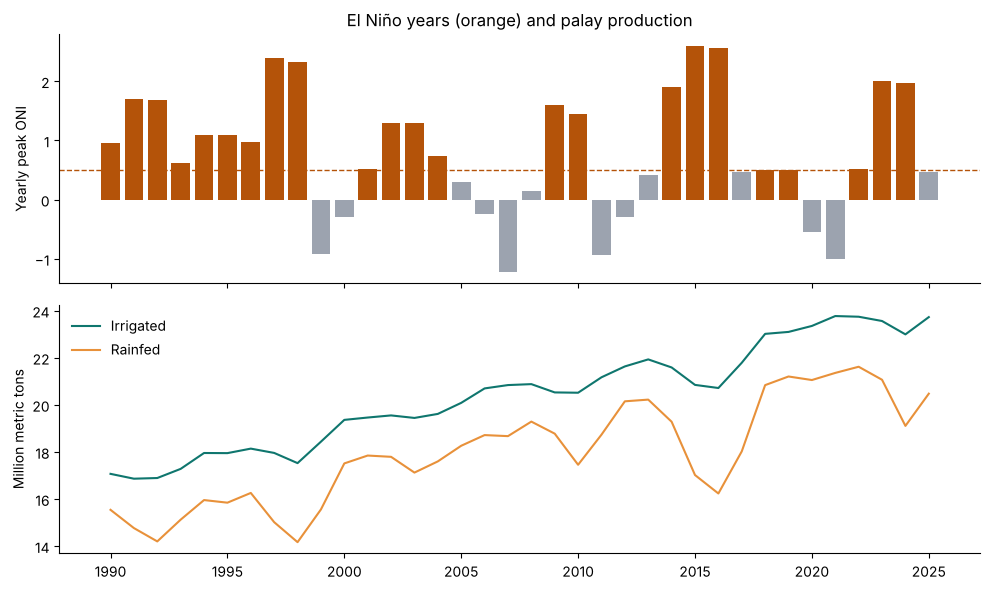

In [5]:
oni_y = tables['oni'].groupby('year')['anomaly'].max()
nat = p.groupby(['year', 'ecosystem'])['production_mt'].sum().unstack() / 1e6
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].bar(oni_y.index, oni_y, color=['#B45309' if v >= 0.5 else '#9CA3AF' for v in oni_y]); ax[0].axhline(0.5, ls='--', c='#B45309', lw=1)
ax[0].set_ylabel('Yearly peak ONI'); ax[0].set_title('El Niño years (orange) and palay production')
ax[1].plot(nat.index, nat['irrigated'], c='#0F766E', label='Irrigated'); ax[1].plot(nat.index, nat['rainfed'], c='#E8913A', label='Rainfed')
ax[1].set_ylabel('Million metric tons'); ax[1].legend(frameon=False)
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

## 5. The harvest lag: same year or the year after?
Correlation between rainfed production change and the ONI peak of the same year vs. the year before. The stronger one tells us which ONI to feed the model (we use both).

In [6]:
t = build_training_table(tables['oni'], tables['palay_production'], tables['rainfall'])
t[['rainfed_change', 'oni_max', 'oni_max_prev', 'rain_dev', 'rain_dev_prev', 'rainfed_share']].corr()['rainfed_change'].drop('rainfed_change').round(2).to_frame('correlation with rainfed change')

,correlation with rainfed change
oni_max,-0.55
oni_max_prev,-0.52
rain_dev,0.51
rain_dev_prev,0.62
rainfed_share,0.00


## 6. Rainfed vs. irrigated loss in each El Niño event

In [7]:
from app.analysis import EVENTS, production_change
pd.DataFrame([{'event': e.key, **production_change(tables['palay_production'], e)} for e in EVENTS.values()]).set_index('event')

,irrigated,rainfed
event,,
1997-98,-2.7,-11.6
2015-16,-4.6,-18.4
2023-24,-2.7,-10.5


## Findings

*Rewrite this after running on the real data.* Answer, with numbers from the cells above:

1. Is the data clean? Missing values, mismatched region codes and outliers found and how they were fixed.
2. Does production fall in the El Niño year itself or the year after (section 5)?
3. How much more do rainfed farms lose than irrigated ones (section 6)?
4. Which features look most useful for the model?